# Black-Scholes PINN Implementation

In this notebook, I implemented a Physics-Informed Neural Network (PINN) to approximate the solution of the Black-Scholes PDE for a European call option.

The aim is to train a neural network to learn the option price $V(S, \tau)$, where:

- $S$ is the stock price
- $\tau$ is the time to maturity
- $V(S, \tau)$ is the option value

I used $\tau = T - t$, so the Black-Scholes PDE is written in forward time-to-maturity form:

$$\frac{\partial V}{\partial \tau}=\frac{1}{2}\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}+ rS \frac{\partial V}{\partial S}- rV$$

The PINN is trained by minimizing a loss function made up of four parts:

1. PDE loss: measures how well the neural network satisfies the Black-Scholes PDE inside the domain.
2. Lower boundary loss: enforces the option price at the lower stock price boundary.
3. Upper boundary loss: enforces the option price at the upper stock price boundary.
4. Terminal payoff loss: enforces the European call payoff at $\tau = 0$.

For a European call option, the terminal payoff is:

$V(S,0) = \max(S-K,0)$

The boundary conditions used are:

$$V(0,t) = 0, V(S \to \infty,t) = S - Ke^{-r\tau}$$

The model uses the input pair $(S, \tau)$ and outputs an approximation to the option price $V(S, \tau)$.

The fixed parameter set used in this notebook is:

- Strike price: $K = 100$
- Maturity: $T = 1$
- Risk-free rate: $r = 0.05$
- Volatility: $\sigma = 0.2$
- $S_{max} = 3 \cdot K$

Once the PINN is trained, I compared its predicted option prices against the analytical Black-Scholes solution.

In [26]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import gc

torch.set_num_threads(1)

import sys
sys.path.append("..")
from src.pinn import BlackScholesPINN

In [27]:
# Defining parameters.

K = 100  # Strike price
T = 1.0  # Time to maturity
r = 0.05  # Risk-free interest rate
sigma = 0.2  # Volatility
S_max = 3*K # Maximum stock price considered

In [28]:
# Generating training points for the PINN model.

def generate_training_points(N_f=500, N_ic=200, N_bc=200):
    S_f = torch.rand(N_f, 1) * S_max
    tau_f = torch.rand(N_f, 1) * T

    S_ic = torch.rand(N_ic, 1) * S_max
    tau_ic = torch.zeros_like(S_ic)
    V_ic = torch.clamp(S_ic - K, min=0.0)

    tau_lb = torch.rand(N_bc, 1) * T
    S_lb = torch.zeros_like(tau_lb)
    V_lb = torch.zeros_like(tau_lb)

    tau_ub = torch.rand(N_bc, 1) * T
    S_ub = torch.full_like(tau_ub, S_max)
    V_ub = S_max - K * torch.exp(-r * tau_ub)

    return S_f, tau_f, S_ic, tau_ic, V_ic, S_lb, tau_lb, V_lb, S_ub, tau_ub, V_ub

In [29]:
# Defining the loss function for the PINN model.

def pinn_loss(model, training_data):
    S_f, tau_f, S_ic, tau_ic, V_ic, S_lb, tau_lb, V_lb, S_ub, tau_ub, V_ub = training_data

    residual = model.pde_residual(S_f, tau_f, r, sigma)
    loss_pde = torch.mean((residual / K) ** 2)

    V_ic_pred = model(S_ic, tau_ic)
    loss_ic = torch.mean(((V_ic_pred - V_ic) / K) ** 2)

    V_lb_pred = model(S_lb, tau_lb)
    loss_lb = torch.mean(((V_lb_pred - V_lb) / K) ** 2)

    V_ub_pred = model(S_ub, tau_ub)
    loss_ub = torch.mean(((V_ub_pred - V_ub) / K) ** 2)

    total_loss = loss_pde + loss_ic + loss_lb + loss_ub

    return total_loss, loss_pde, loss_ic, loss_lb, loss_ub

In [30]:
# Training the PINN model.

model = BlackScholesPINN(
    layers=[2, 32, 32, 32, 1],
    S_max=S_max,
    T=T,
    price_scale=K
)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

loss_history = []

epochs = 2000


def train_step():
    training_data = generate_training_points(N_f=200, N_ic=100, N_bc=100)

    optimizer.zero_grad(set_to_none=True)

    total_loss, loss_pde, loss_ic, loss_lb, loss_ub = pinn_loss(model, training_data)

    total_loss.backward()
    optimizer.step()

    values = (
        total_loss.detach().item(),
        loss_pde.detach().item(),
        loss_ic.detach().item(),
        loss_lb.detach().item(),
        loss_ub.detach().item()
    )

    del training_data
    del total_loss, loss_pde, loss_ic, loss_lb, loss_ub

    return values


for epoch in range(epochs):
    total, pde, ic, lb, ub = train_step()

    loss_history.append(total)

    if epoch % 100 == 0:
        gc.collect()

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Total={total:.6e}, "
            f"PDE={pde:.6e}, "
            f"IC={ic:.6e}, "
            f"LB={lb:.6e}, "
            f"UB={ub:.6e}"
        )

Epoch 0: Total=5.370657e+00, PDE=3.388939e-04, IC=9.254216e-01, LB=9.976722e-04, UB=4.443899e+00
Epoch 500: Total=2.483924e-02, PDE=2.649492e-03, IC=1.704869e-02, LB=4.449458e-03, UB=6.915986e-04
Epoch 1000: Total=5.697421e-03, PDE=1.305646e-03, IC=3.677846e-03, LB=4.818547e-04, UB=2.320756e-04
Epoch 1500: Total=3.762249e-03, PDE=1.312298e-03, IC=2.157590e-03, LB=1.549196e-05, UB=2.768691e-04


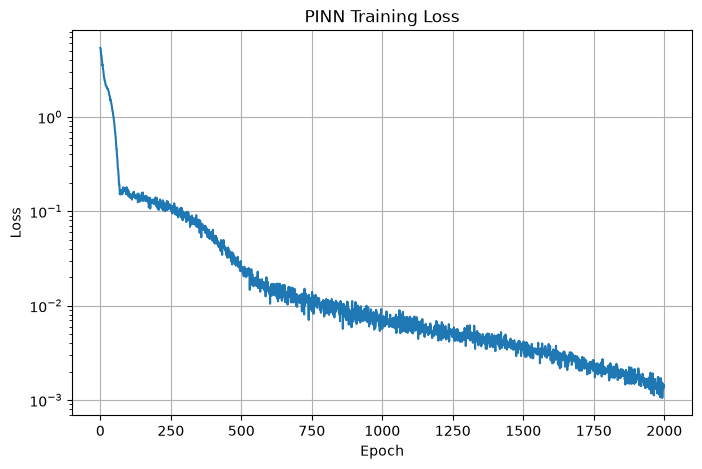

In [31]:
# Visualizing the training loss history.

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("PINN Training Loss")
plt.grid(True)
plt.show()